In [1]:
%pip install ultralytics

     ---------------------------------------- 0.0/46.7 kB ? eta -:--:--
     -------- ------------------------------- 10.2/46.7 kB ? eta -:--:--
     ---------------- --------------------- 20.5/46.7 kB 217.9 kB/s eta 0:00:01
     --------------------------------- ---- 41.0/46.7 kB 217.9 kB/s eta 0:00:01
     -------------------------------------- 46.7/46.7 kB 233.9 kB/s eta 0:00:00
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached torch-2.14.0-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.0-cp312


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Treinamento YOLOv8 de segmentação

In [1]:
import filecmp
import json
import random
import shutil
from pathlib import Path

from PIL import Image

PASTA_BASE = Path.cwd()
PASTA_ORIGEM = PASTA_BASE / "imagens_rotuladas_consolidadas"
PASTA_RUAS_LIMPAS = PASTA_BASE / "imagens_classificadas_ruas_limpas"
PASTA_DATASET = PASTA_BASE / "dataset"
PASTA_LABELS_ORIGEM = PASTA_ORIGEM / "labels"
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff", ".avif"}
NOMES_CLASSES = ["lixo_solto", "lixo_contido", "entulho"]
MAPA_CLASSES = {
    "lixo_solto": 0,
    "lixo": 0,
    "lixo_contido": 1,
    "entulho": 2,
}
SEMENTE = 42

if not PASTA_ORIGEM.is_dir() or not PASTA_LABELS_ORIGEM.is_dir():
    raise FileNotFoundError(
        f"Não encontrei a pasta consolidada de imagens e rótulos: {PASTA_ORIGEM}"
    )
if not PASTA_RUAS_LIMPAS.is_dir():
    raise FileNotFoundError(f"Pasta de ruas limpas não encontrada: {PASTA_RUAS_LIMPAS}")

imagens_por_nome = {}
for caminho_imagem in PASTA_ORIGEM.iterdir():
    if caminho_imagem.is_file() and caminho_imagem.suffix.casefold() in EXTENSOES_IMAGEM:
        chave = caminho_imagem.stem.casefold()
        if chave in imagens_por_nome:
            raise ValueError(f"Há imagens com o mesmo nome-base: {chave}")
        imagens_por_nome[chave] = caminho_imagem

registros = []
contagem_classes = {nome: 0 for nome in NOMES_CLASSES}
for caminho_json in sorted(PASTA_LABELS_ORIGEM.glob("*.json")):
    caminho_imagem = imagens_por_nome.get(caminho_json.stem.casefold())
    if caminho_imagem is None:
        raise FileNotFoundError(f"Imagem correspondente não encontrada para {caminho_json.name}")

    dados = json.loads(caminho_json.read_text(encoding="utf-8"))
    linhas_rotulos = []
    classes_da_imagem = set()
    with Image.open(caminho_imagem) as imagem:
        largura, altura = imagem.size

    if largura <= 0 or altura <= 0:
        raise ValueError(f"Dimensões inválidas em {caminho_imagem.name}")

    for forma in dados.get("shapes", []):
        nome_rotulo = str(forma.get("label", "")).strip()
        if nome_rotulo not in MAPA_CLASSES:
            raise ValueError(f"Classe sem mapeamento em {caminho_json.name}: {nome_rotulo!r}")
        if forma.get("shape_type") != "polygon":
            raise ValueError(f"Anotação que não é polígono em {caminho_json.name}")

        pontos = forma.get("points", [])
        if len(pontos) < 3:
            raise ValueError(f"Polígono com menos de 3 pontos em {caminho_json.name}")

        valores = []
        for x, y in pontos:
            x_normalizado = min(1.0, max(0.0, float(x) / largura))
            y_normalizado = min(1.0, max(0.0, float(y) / altura))
            valores.extend((x_normalizado, y_normalizado))

        indice_classe = MAPA_CLASSES[nome_rotulo]
        linhas_rotulos.append(
            str(indice_classe) + " " + " ".join(f"{valor:.6f}" for valor in valores)
        )
        classes_da_imagem.add(indice_classe)
        contagem_classes[NOMES_CLASSES[indice_classe]] += 1

    registros.append(
        {
            "imagem": caminho_imagem,
            "rotulos": "\n".join(linhas_rotulos),
            "classes": classes_da_imagem,
        }
    )

nomes_imagens_usados = set(imagens_por_nome)
registros_negativos = []
for caminho_imagem in sorted(PASTA_RUAS_LIMPAS.rglob("*")):
    if not caminho_imagem.is_file() or caminho_imagem.suffix.casefold() not in EXTENSOES_IMAGEM:
        continue
    chave = caminho_imagem.stem.casefold()
    if chave in nomes_imagens_usados:
        raise ValueError(f"Nome de imagem duplicado entre as bases: {caminho_imagem.name}")
    nomes_imagens_usados.add(chave)
    registro_negativo = {"imagem": caminho_imagem, "rotulos": "", "classes": set()}
    registros.append(registro_negativo)
    registros_negativos.append(registro_negativo)

if len(registros) < 2:
    raise ValueError("São necessárias pelo menos duas imagens para treino e validação.")

classes_presentes = set().union(*(registro["classes"] for registro in registros))
tamanho_validacao = max(1, round(len(registros) * 0.2))
for tentativa in range(1000):
    embaralhados = list(registros)
    random.Random(SEMENTE + tentativa).shuffle(embaralhados)
    validacao = embaralhados[:tamanho_validacao]
    treino = embaralhados[tamanho_validacao:]
    classes_treino = set().union(*(registro["classes"] for registro in treino))
    classes_validacao = set().union(*(registro["classes"] for registro in validacao))
    if classes_presentes.issubset(classes_treino) and classes_presentes.issubset(classes_validacao):
        break
else:
    raise ValueError(
        "Não foi possível dividir o dataset mantendo cada classe anotada em treino e validação."
    )

for divisao in ("train", "val"):
    (PASTA_DATASET / "images" / divisao).mkdir(parents=True, exist_ok=True)
    (PASTA_DATASET / "labels" / divisao).mkdir(parents=True, exist_ok=True)

# Reorganiza apenas cópias pré-existentes correspondentes às imagens de entrada.
for registro in registros:
    caminho_imagem = registro["imagem"]
    nome_rotulo = f"{caminho_imagem.stem}.txt"
    for divisao in ("train", "val"):
        imagem_existente = PASTA_DATASET / "images" / divisao / caminho_imagem.name
        rotulo_existente = PASTA_DATASET / "labels" / divisao / nome_rotulo
        if imagem_existente.exists():
            if not filecmp.cmp(caminho_imagem, imagem_existente, shallow=False):
                raise FileExistsError(f"Já existe uma imagem diferente: {imagem_existente}")
            imagem_existente.unlink()
        if rotulo_existente.exists():
            if rotulo_existente.read_text(encoding="utf-8") != registro["rotulos"]:
                raise FileExistsError(f"Já existe um rótulo diferente: {rotulo_existente}")
            rotulo_existente.unlink()

for divisao, registros_divisao in (("train", treino), ("val", validacao)):
    for registro in registros_divisao:
        caminho_imagem = registro["imagem"]
        destino_imagem = PASTA_DATASET / "images" / divisao / caminho_imagem.name
        destino_rotulo = PASTA_DATASET / "labels" / divisao / f"{caminho_imagem.stem}.txt"
        shutil.copy2(caminho_imagem, destino_imagem)
        destino_rotulo.write_text(registro["rotulos"], encoding="utf-8")

conteudo_yaml = (
    f"path: '{PASTA_DATASET.as_posix()}'\n"
    "train: images/train\n"
    "val: images/val\n\n"
    "names:\n"
    "  0: lixo_solto\n"
    "  1: lixo_contido\n"
    "  2: entulho\n"
)
(PASTA_DATASET / "dataset.yaml").write_text(conteudo_yaml, encoding="utf-8")

print(f"Dataset YOLO criado em: {PASTA_DATASET}")
print(f"Imagens de treino: {len(treino)} | imagens de validação: {len(validacao)}")
print(f"Imagens limpas sem objetos (negativas): {len(registros_negativos)}")
print("Polígonos por classe:")
for nome_classe, quantidade in contagem_classes.items():
    print(f"  {nome_classe}: {quantidade}")
print(f"Configuração: {PASTA_DATASET / 'dataset.yaml'}")

Dataset YOLO criado em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\dataset
Imagens de treino: 117 | imagens de validação: 29
Imagens limpas sem objetos (negativas): 32
Polígonos por classe:
  lixo_solto: 366
  lixo_contido: 0
  entulho: 13
Configuração: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\dataset\dataset.yaml


In [2]:
import os
import torch
from ultralytics import YOLO


DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 0 if os.name == "nt" else 2


def treinar_modelo():
    modelo = YOLO("yolov8n-seg.pt")
    resultados = modelo.train(
        data=str(PASTA_DATASET / "dataset.yaml"),
        epochs=100,
        imgsz=640,
        batch=8,
        workers=WORKERS,
        name="yolo_lixo_urbano",
        degrees=15.0,
        flipud=0.0,
        fliplr=0.5,
        mosaic=1.0,
        save=True,
        plots=True,
        device=DEVICE,
        seed=42,
    )

    caminho_best = Path(resultados.save_dir) / "weights" / "best.pt"
    print("Treinamento concluído com sucesso!")
    print(f"Dispositivo: {DEVICE} | workers: {WORKERS}")
    print(f"Pesos do modelo salvos em: {caminho_best}")
    return resultados


resultados_treino = treinar_modelo()

Ultralytics 8.4.165  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\alexa\Downloads\Teste Base de Imagens TCC\dataset\dataset.yaml, degrees=15.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

## Teste visual do modelo treinado

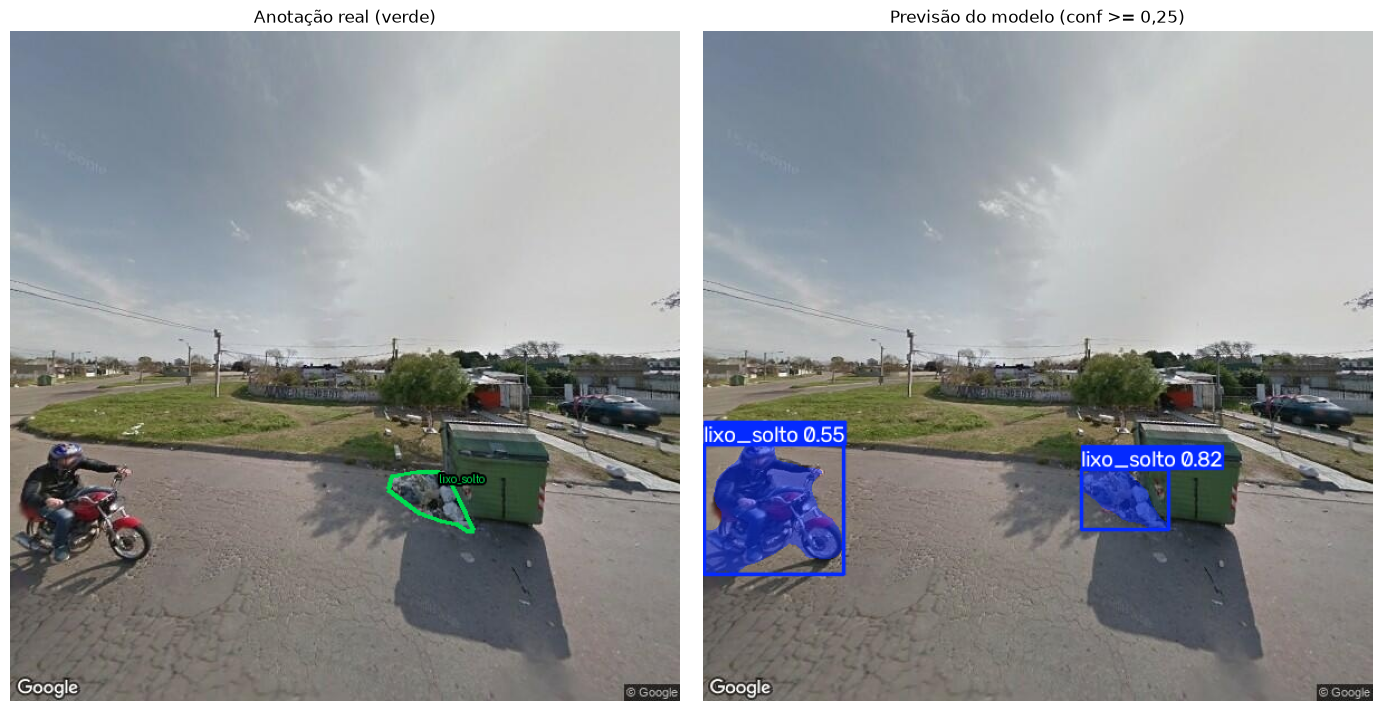

Imagem de previsão salva em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\predicoes\01941_06_predicao.jpg
Comparação salva em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\predicoes\01941_06_comparacao.jpg
Imagem usada no treino: True
Detecções encontradas: 2
  lixo_solto: confiança 0.821
  lixo_solto: confiança 0.550
  IoU das máscaras para lixo_solto: 0.178


In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from ultralytics import YOLO

CAMINHO_PESOS = PASTA_BASE / "runs" / "segment" / "yolo_lixo_urbano-2" / "weights" / "best.pt"
CAMINHO_IMAGEM_TESTE = PASTA_BASE / "imagens_rotuladas_consolidadas" / "01941_06.jpg"
CAMINHO_JSON_TESTE = PASTA_BASE / "imagens_rotuladas_consolidadas" / "labels" / "01941_06.json"
PASTA_RESULTADOS = PASTA_BASE / "runs" / "segment" / "yolo_lixo_urbano-2" / "predicoes"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

for caminho in (CAMINHO_PESOS, CAMINHO_IMAGEM_TESTE, CAMINHO_JSON_TESTE):
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo necessário não encontrado: {caminho}")

modelo_teste = YOLO(str(CAMINHO_PESOS))
resultado = modelo_teste.predict(
    source=str(CAMINHO_IMAGEM_TESTE),
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False,
)[0]

caminho_predicao = PASTA_RESULTADOS / f"{CAMINHO_IMAGEM_TESTE.stem}_predicao.jpg"
resultado.save(filename=str(caminho_predicao))

imagem_original = Image.open(CAMINHO_IMAGEM_TESTE).convert("RGB")
imagem_real = imagem_original.copy()
desenho = ImageDraw.Draw(imagem_real)
dados_rotulo = json.loads(CAMINHO_JSON_TESTE.read_text(encoding="utf-8"))

nomes_classes = modelo_teste.names
classes_reais = set()
for forma in dados_rotulo.get("shapes", []):
    nome_classe = str(forma.get("label", "")).strip()
    indice_classe = MAPA_CLASSES.get(nome_classe)
    if indice_classe is None:
        continue
    classes_reais.add(indice_classe)
    pontos = [tuple(ponto) for ponto in forma.get("points", [])]
    if len(pontos) >= 3:
        cor = (0, 220, 80)
        desenho.line(pontos + [pontos[0]], fill=cor, width=4)
        desenho.text(pontos[0], nomes_classes[indice_classe], fill=cor, stroke_width=2, stroke_fill=(0, 0, 0))

imagem_prevista = Image.fromarray(resultado.plot()[:, :, ::-1])
caminho_comparacao = PASTA_RESULTADOS / f"{CAMINHO_IMAGEM_TESTE.stem}_comparacao.jpg"
fig, eixos = plt.subplots(1, 2, figsize=(14, 7))
eixos[0].imshow(imagem_real)
eixos[0].set_title("Anotação real (verde)")
eixos[1].imshow(imagem_prevista)
eixos[1].set_title("Previsão do modelo (conf >= 0,25)")
for eixo in eixos:
    eixo.axis("off")
fig.tight_layout()
fig.savefig(caminho_comparacao, dpi=150, bbox_inches="tight")
plt.show()

print(f"Imagem de previsão salva em: {caminho_predicao}")
print(f"Comparação salva em: {caminho_comparacao}")
print(f"Imagem usada no treino: {(PASTA_DATASET / 'images' / 'train' / CAMINHO_IMAGEM_TESTE.name).is_file()}")

if resultado.boxes is None or len(resultado.boxes) == 0:
    print("O modelo não detectou objetos com confiança >= 0,25.")
else:
    classes_previstas = resultado.boxes.cls.cpu().numpy().astype(int)
    confiancas = resultado.boxes.conf.cpu().numpy()
    print(f"Detecções encontradas: {len(classes_previstas)}")
    for indice_classe, confianca in zip(classes_previstas, confiancas):
        print(f"  {nomes_classes[indice_classe]}: confiança {confianca:.3f}")

    masks = resultado.masks.data.cpu().numpy() if resultado.masks is not None else None
    if masks is not None:
        altura, largura = imagem_original.height, imagem_original.width
        classes_previstas_por_indice = resultado.boxes.cls.cpu().numpy().astype(int)
        for indice_classe in sorted(classes_reais):
            mascara_real = Image.new("1", (largura, altura), 0)
            desenho_mascara = ImageDraw.Draw(mascara_real)
            for forma in dados_rotulo.get("shapes", []):
                rotulo_classe = MAPA_CLASSES.get(str(forma.get("label", "")).strip())
                pontos = [tuple(ponto) for ponto in forma.get("points", [])]
                if rotulo_classe == indice_classe and len(pontos) >= 3:
                    desenho_mascara.polygon(pontos, fill=1)

            mascara_predita = np.zeros((altura, largura), dtype=bool)
            for indice_mascara, classe_predita in enumerate(classes_previstas_por_indice):
                if classe_predita != indice_classe:
                    continue
                mascara = Image.fromarray(masks[indice_mascara].astype(np.uint8) * 255)
                if mascara.size != (largura, altura):
                    mascara = mascara.resize((largura, altura), Image.Resampling.NEAREST)
                mascara_predita |= np.asarray(mascara) > 0

            pixels_reais = np.asarray(mascara_real, dtype=bool)
            intersecao = np.logical_and(pixels_reais, mascara_predita).sum()
            uniao = np.logical_or(pixels_reais, mascara_predita).sum()
            iou_classe = intersecao / uniao if uniao else float("nan")
            print(f"  IoU das máscaras para {nomes_classes[indice_classe]}: {iou_classe:.3f}")

if not classes_reais:
    print("O JSON não contém polígonos para comparar nesta imagem.")

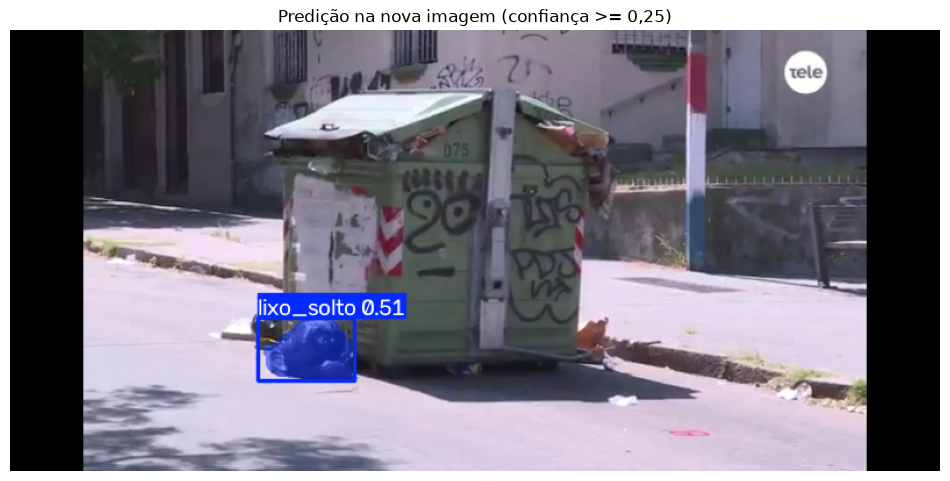

Imagem de entrada: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\WhatsApp Image 2020-12-29 at 5.02.34 PM (3).jpeg
Resultado salvo em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\predicoes\WhatsApp Image 2020-12-29 at 5.02.34 PM (3)_predicao.jpg
Detecções encontradas: 1
  lixo_solto: confiança 0.509


In [4]:
CAMINHO_IMAGEM_NOVA = PASTA_BASE / "WhatsApp Image 2020-12-29 at 5.02.34 PM (3).jpeg"
CAMINHO_RESULTADO_NOVO = PASTA_RESULTADOS / f"{CAMINHO_IMAGEM_NOVA.stem}_predicao.jpg"

if not CAMINHO_IMAGEM_NOVA.is_file():
    raise FileNotFoundError(f"Imagem de teste não encontrada: {CAMINHO_IMAGEM_NOVA}")

resultado_novo = modelo_teste.predict(
    source=str(CAMINHO_IMAGEM_NOVA),
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False,
)[0]
resultado_novo.save(filename=str(CAMINHO_RESULTADO_NOVO))

imagem_nova_anotada = Image.fromarray(resultado_novo.plot()[:, :, ::-1])
plt.figure(figsize=(12, 7))
plt.imshow(imagem_nova_anotada)
plt.axis("off")
plt.title("Predição na nova imagem (confiança >= 0,25)")
plt.show()

print(f"Imagem de entrada: {CAMINHO_IMAGEM_NOVA}")
print(f"Resultado salvo em: {CAMINHO_RESULTADO_NOVO}")
if resultado_novo.boxes is None or len(resultado_novo.boxes) == 0:
    print("Nenhum objeto detectado com confiança >= 0,25.")
else:
    classes_novas = resultado_novo.boxes.cls.cpu().numpy().astype(int)
    confiancas_novas = resultado_novo.boxes.conf.cpu().numpy()
    print(f"Detecções encontradas: {len(classes_novas)}")
    for indice_classe, confianca in zip(classes_novas, confiancas_novas):
        print(f"  {modelo_teste.names[indice_classe]}: confiança {confianca:.3f}")

Verificação SHA-256: imagem ausente dos conjuntos train e val.


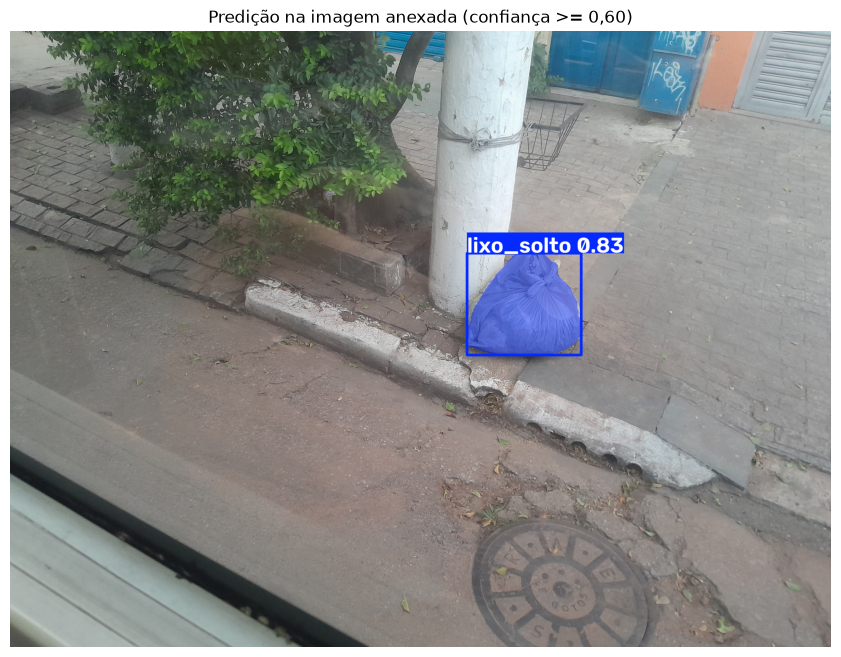

Imagem de entrada: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\20260327_180118.jpg
Resultado salvo em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\predicoes\20260327_180118_predicao.jpg
Detecções encontradas: 1
  lixo_solto: confiança 0.826


In [6]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PASTA_BASE = Path.cwd()
CAMINHO_PESOS_NOVO = PASTA_BASE / "runs" / "segment" / "yolo_lixo_urbano-2" / "weights" / "best.pt"
CAMINHO_IMAGEM_ANEXA = PASTA_BASE / "20260327_180118.jpg"
PASTA_PREDICOES = PASTA_BASE / "runs" / "segment" / "yolo_lixo_urbano-2" / "predicoes"
PASTA_PREDICOES.mkdir(parents=True, exist_ok=True)
CAMINHO_SAIDA_ANEXA = PASTA_PREDICOES / f"{CAMINHO_IMAGEM_ANEXA.stem}_predicao.jpg"

for caminho in (CAMINHO_PESOS_NOVO, CAMINHO_IMAGEM_ANEXA):
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo necessário não encontrado: {caminho}")

def sha256_arquivo(caminho):
    digest = hashlib.sha256()
    with caminho.open("rb") as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
            digest.update(bloco)
    return digest.hexdigest()

hash_imagem_anexa = sha256_arquivo(CAMINHO_IMAGEM_ANEXA)
correspondencias_dataset = []
for divisao in ("train", "val"):
    pasta_divisao = PASTA_BASE / "dataset" / "images" / divisao
    for imagem_dataset in pasta_divisao.iterdir():
        if imagem_dataset.is_file() and sha256_arquivo(imagem_dataset) == hash_imagem_anexa:
            correspondencias_dataset.append((divisao, imagem_dataset.name))

if correspondencias_dataset:
    print(f"A imagem já existe no dataset: {correspondencias_dataset}")
else:
    print("Verificação SHA-256: imagem ausente dos conjuntos train e val.")

modelo_imagem_anexa = YOLO(str(CAMINHO_PESOS_NOVO))
resultado_imagem_anexa = modelo_imagem_anexa.predict(
    source=str(CAMINHO_IMAGEM_ANEXA),
    conf=0.60,
    iou=0.7,
    device="cpu",
    verbose=False,
)[0]
resultado_imagem_anexa.save(filename=str(CAMINHO_SAIDA_ANEXA))

visualizacao_anexa = Image.fromarray(resultado_imagem_anexa.plot()[:, :, ::-1])
plt.figure(figsize=(12, 8))
plt.imshow(visualizacao_anexa)
plt.axis("off")
plt.title("Predição na imagem anexada (confiança >= 0,60)")
plt.show()

print(f"Imagem de entrada: {CAMINHO_IMAGEM_ANEXA}")
print(f"Resultado salvo em: {CAMINHO_SAIDA_ANEXA}")
if resultado_imagem_anexa.boxes is None or len(resultado_imagem_anexa.boxes) == 0:
    print("Nenhum objeto detectado com confiança >= 0,60.")
else:
    classes_anexa = resultado_imagem_anexa.boxes.cls.cpu().numpy().astype(int)
    confiancas_anexa = resultado_imagem_anexa.boxes.conf.cpu().numpy()
    print(f"Detecções encontradas: {len(classes_anexa)}")
    for indice_classe, confianca in zip(classes_anexa, confiancas_anexa):
        print(f"  {modelo_imagem_anexa.names[indice_classe]}: confiança {confianca:.3f}")

Verificação SHA-256: imagem não encontrada em train nem val.


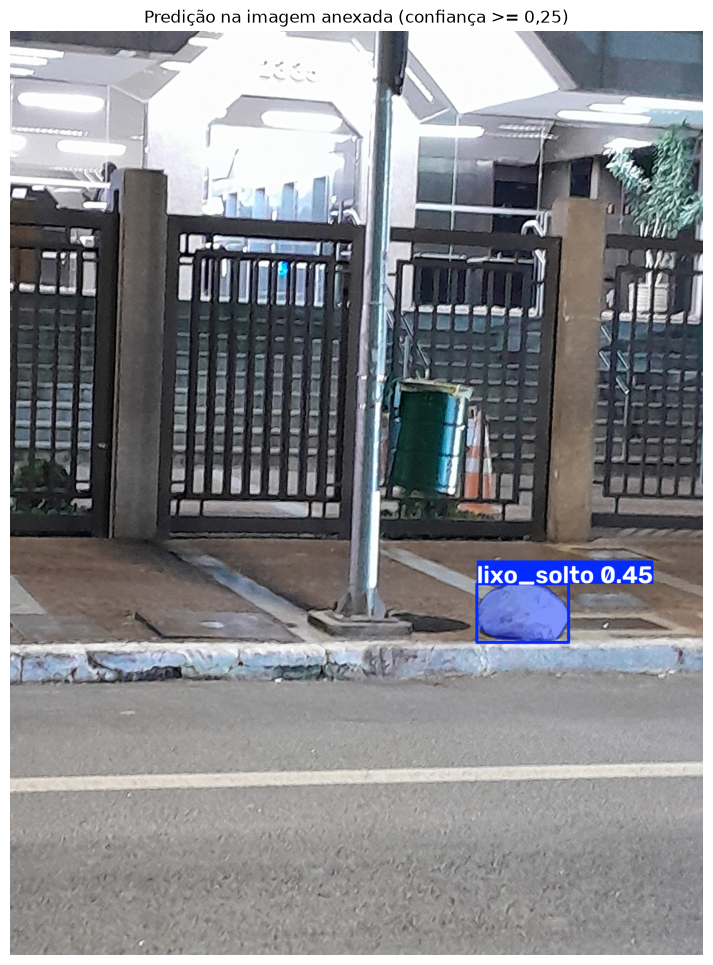

Imagem de entrada: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\20260304_201319.jpg
Imagem anotada salva em: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\predicoes\20260304_201319_predicao.jpg
Detecções encontradas: 1
  lixo_solto: confiança 0.452


In [12]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PASTA_PROJETO = Path.cwd()
CAMINHO_MODELO_POSTE = PASTA_PROJETO / "runs" / "segment" / "yolo_lixo_urbano-2" / "weights" / "best.pt"
CAMINHO_IMAGEM_POSTE = PASTA_PROJETO / "20260304_201319.jpg"
PASTA_SAIDA_POSTE = PASTA_PROJETO / "runs" / "segment" / "yolo_lixo_urbano-2" / "predicoes"
PASTA_SAIDA_POSTE.mkdir(parents=True, exist_ok=True)
CAMINHO_PREDICAO_POSTE = PASTA_SAIDA_POSTE / f"{CAMINHO_IMAGEM_POSTE.stem}_predicao.jpg"

for caminho in (CAMINHO_MODELO_POSTE, CAMINHO_IMAGEM_POSTE):
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo necessário não encontrado: {caminho}")

def calcular_sha256(caminho):
    digest = hashlib.sha256()
    with caminho.open("rb") as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
            digest.update(bloco)
    return digest.hexdigest()

hash_imagem_poste = calcular_sha256(CAMINHO_IMAGEM_POSTE)
correspondencias_poste = []
for nome_split in ("train", "val"):
    pasta_split = PASTA_PROJETO / "dataset" / "images" / nome_split
    for imagem_split in pasta_split.iterdir():
        if imagem_split.is_file() and calcular_sha256(imagem_split) == hash_imagem_poste:
            correspondencias_poste.append((nome_split, imagem_split.name))

if correspondencias_poste:
    print(f"A imagem consta no dataset: {correspondencias_poste}")
else:
    print("Verificação SHA-256: imagem não encontrada em train nem val.")

modelo_poste = YOLO(str(CAMINHO_MODELO_POSTE))
resultado_poste = modelo_poste.predict(
    source=str(CAMINHO_IMAGEM_POSTE),
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False,
)[0]
resultado_poste.save(filename=str(CAMINHO_PREDICAO_POSTE))

imagem_poste_anotada = Image.fromarray(resultado_poste.plot()[:, :, ::-1])
plt.figure(figsize=(10, 12))
plt.imshow(imagem_poste_anotada)
plt.axis("off")
plt.title("Predição na imagem anexada (confiança >= 0,25)")
plt.show()

print(f"Imagem de entrada: {CAMINHO_IMAGEM_POSTE}")
print(f"Imagem anotada salva em: {CAMINHO_PREDICAO_POSTE}")
if resultado_poste.boxes is None or len(resultado_poste.boxes) == 0:
    print("Nenhum objeto detectado com confiança >= 0,25.")
else:
    classes_poste = resultado_poste.boxes.cls.cpu().numpy().astype(int)
    confiancas_poste = resultado_poste.boxes.conf.cpu().numpy()
    print(f"Detecções encontradas: {len(classes_poste)}")
    for indice_classe, confianca in zip(classes_poste, confiancas_poste):
        print(f"  {modelo_poste.names[indice_classe]}: confiança {confianca:.3f}")